# Telecom Customer Churn Analysis

ניתוח נתוני נטישת לקוחות טלקום במסגרת הקורס הדמיית נתונים.

This project explores customer churn using Random Forest, AdaBoost, Logistic Regression, hard/soft voting, PCA, and K-Means preprocessing.

**Question:** Which of the compared approaches best identifies customers who churn?

**Evaluation plan:** a stratified 60% training / 20% validation / 20% test split. We choose the model by validation **F1 for churn**, then refit that choice on training + validation and evaluate it once on the held-out test set. Accuracy, precision, recall and ROC AUC provide context. The test set is not used to select a model.

The explanatory sections follow the assignment in `docs/assignment.pdf`. See `docs/methodology.md` for the analysis protocol and limitations.


## 1 Loading and checking the data

Run all cells in order from a fresh kernel. Paths are relative to this project folder. `customerID` is used only for checking identities and recording the split; `Churn` is the target. Neither is supplied as a predictive feature.


In [1]:
from pathlib import Path
import json
import hashlib
import sys
import time
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

SEED = 42
THREAD_LIMIT = threadpool_limits(limits=1)
ROOT = Path.cwd()
DATA = ROOT / "data/telecom_customers_churn.csv"
if not DATA.is_file():
    raise FileNotFoundError("Open and run this notebook from the telecom-churn-analysis folder.")
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 25)

def show_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()

df = pd.read_csv(DATA)
raw_columns = list(df.columns)
assert df.shape == (7043, 21), "The supplied coursework dataset has changed."
assert df["customerID"].is_unique
assert set(df["Churn"].unique()) == {"No", "Yes"}
blank_charges = int(df["TotalCharges"].astype(str).str.strip().eq("").sum())
# This conversion is deterministic; imputation is learned later from training data only.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"Customers: {len(df):,}; columns: {df.shape[1]}; blank TotalCharges values: {blank_charges}")
display(df.head())
quality = pd.DataFrame({"type": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(quality)
quality.to_csv(RESULTS / "data_quality.csv")


Customers: 7,043; columns: 21; blank TotalCharges values: 11


,customerID,Gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,type,missing,unique
customerID,str,0,7043
Gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


`TotalCharges` contains 11 blank strings in the supplied file. They become missing numeric values. A median imputer, fitted within each training pipeline, handles them. There are no duplicated customer IDs.

## 2 A fixed split before exploration and preprocessing

All exploratory charts below use the training partition. Validation is used for comparing the predefined candidates. Test rows remain separate until the final evaluation. Stratification keeps the churn proportions similar across partitions.


In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
all_idx = np.arange(len(df))
development_idx, test_idx = train_test_split(all_idx, test_size=0.20, random_state=SEED, stratify=y)
train_idx, validation_idx = train_test_split(development_idx, test_size=0.25, random_state=SEED, stratify=y.iloc[development_idx])
assert set(train_idx).isdisjoint(validation_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(validation_idx).isdisjoint(test_idx)
assert set(train_idx) | set(validation_idx) | set(test_idx) == set(all_idx)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_validation, y_validation = X.iloc[validation_idx], y.iloc[validation_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
train_frame = df.iloc[train_idx].copy()
train_frame["churn_flag"] = y_train
split = pd.DataFrame({"customerID": df["customerID"], "partition": ""})
for label, indices in [("train", train_idx), ("validation", validation_idx), ("test", test_idx)]:
    split.loc[indices, "partition"] = label
split.to_csv(RESULTS / "split_membership.csv", index=False)
display(pd.DataFrame([
    {"partition": label, "rows": len(idx), "churn_rate": float(y.iloc[idx].mean())}
    for label, idx in [("train", train_idx), ("validation", validation_idx), ("test", test_idx)]
]))


,partition,rows,churn_rate
0,train,4225,0.265325
1,validation,1409,0.265436
2,test,1409,0.265436


## 3 Exploring the churn patterns

These are descriptive associations in the training sample. Differences between groups do not establish causation or statistical significance. In particular, `Partner` records partnership status and is not a direct measurement of marital status.


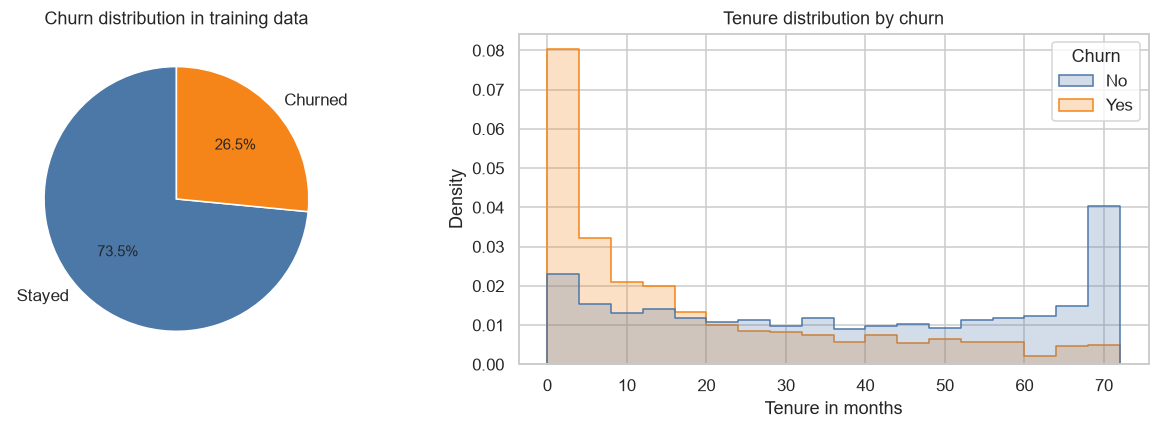

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = train_frame["Churn"].value_counts().reindex(["No", "Yes"])
axes[0].pie(counts, labels=["Stayed", "Churned"], autopct="%.1f%%", colors=["#4c78a8", "#f58518"], startangle=90)
axes[0].set_title("Churn distribution in training data")
sns.histplot(data=train_frame, x="tenure", hue="Churn", bins=18, stat="density", common_norm=False,
             element="step", palette={"No": "#4c78a8", "Yes": "#f58518"}, ax=axes[1])
axes[1].set(title="Tenure distribution by churn", xlabel="Tenure in months")
show_plot("01_churn_and_tenure.png")


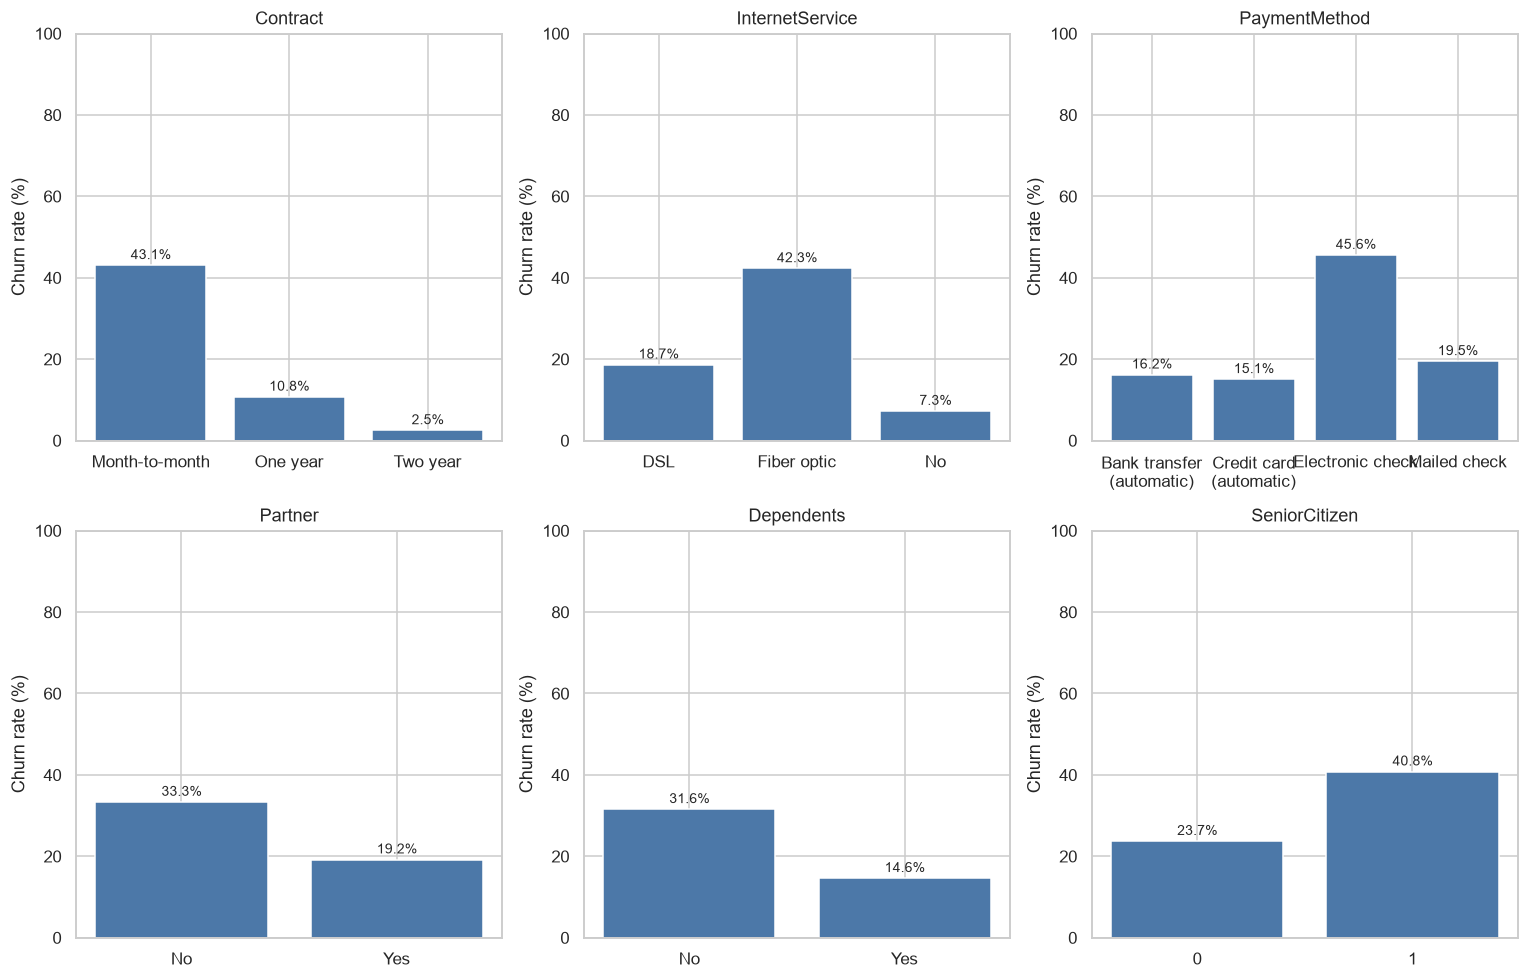

,customers,churned,churn_rate_percent
Contract,,,
Month-to-month,2326,1002,43.08
One year,865,93,10.75
Two year,1034,26,2.51


In [4]:
from textwrap import fill
group_columns = ["Contract", "InternetService", "PaymentMethod", "Partner", "Dependents", "SeniorCitizen",
                 "Gender", "PhoneService", "MultipleLines", "PaperlessBilling"]
group_tables = {}
for column in group_columns:
    table = train_frame.groupby(column, observed=True)["churn_flag"].agg(customers="size", churned="sum")
    table["churn_rate_percent"] = 100 * table["churned"] / table["customers"]
    group_tables[column] = table
pd.concat(group_tables, names=["feature", "category"]).to_csv(RESULTS / "group_churn_rates.csv")
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, column in zip(axes.ravel(), group_columns[:6]):
    table = group_tables[column]
    ax.bar([fill(str(v), 17) for v in table.index], table["churn_rate_percent"], color="#4c78a8")
    ax.set(title=column, ylabel="Churn rate (%)", ylim=(0, 100))
    for i, rate in enumerate(table["churn_rate_percent"]):
        ax.text(i, rate + 1.5, f"{rate:.1f}%", ha="center", fontsize=9)
show_plot("02_group_churn_rates.png")
display(group_tables["Contract"].round(2))


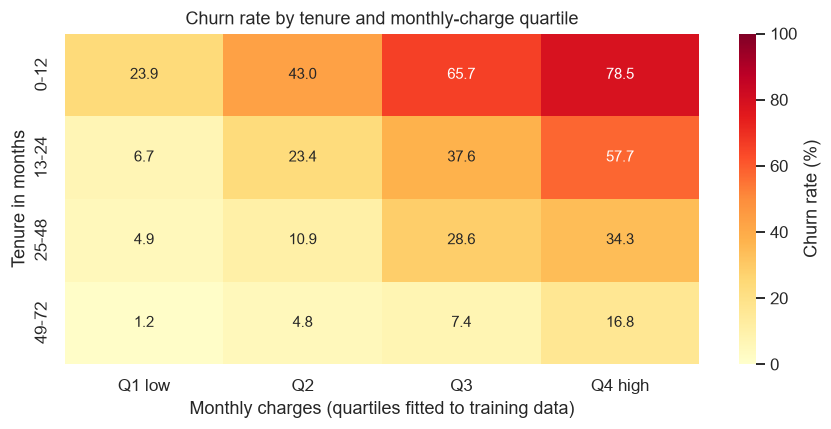

In [5]:
heat_frame = train_frame.assign(
    tenure_group=pd.cut(train_frame["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]),
    charge_quartile=pd.qcut(train_frame["MonthlyCharges"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]),
)
heat = heat_frame.pivot_table(index="tenure_group", columns="charge_quartile", values="churn_flag", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(8, 4))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100, cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate by tenure and monthly-charge quartile")
plt.xlabel("Monthly charges (quartiles fitted to training data)")
plt.ylabel("Tenure in months")
show_plot("03_tenure_charge_heatmap.png")


## 4 Feature engineering

**SubscribedServiceCount** counts six services to which a customer subscribes. It uses only that customer's existing feature values, never the target.


,customers,churn_rate
SubscribedServiceCount,,
0,1322,0.212557
1,568,0.452465
2,632,0.363924
3,654,0.285933
4,523,0.221797
5,350,0.120000
6,176,0.045455


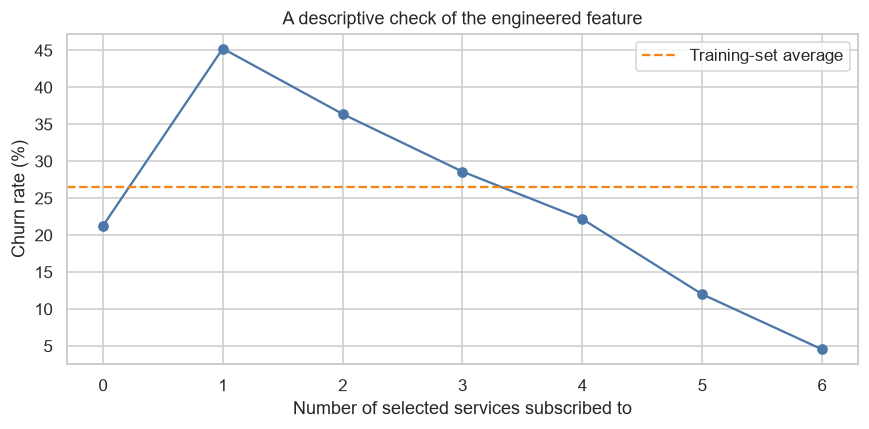

In [6]:
SERVICE_COLUMNS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_service_count(frame):
    out = frame.copy()
    out["SubscribedServiceCount"] = out[SERVICE_COLUMNS].eq("Yes").sum(axis=1)
    return out

feature_frame = add_service_count(train_frame)
service_summary = feature_frame.groupby("SubscribedServiceCount")["churn_flag"].agg(customers="size", churn_rate="mean")
display(service_summary)
plt.figure(figsize=(8, 4))
plt.plot(service_summary.index, service_summary["churn_rate"] * 100, "o-", color="#4c78a8")
plt.axhline(y_train.mean() * 100, color="#f58518", linestyle="--", label="Training-set average")
plt.xlabel("Number of selected services subscribed to")
plt.ylabel("Churn rate (%)")
plt.title("A descriptive check of the engineered feature")
plt.legend()
show_plot("04_service_count.png")


## 5 Preprocessing, PCA and K-Means

All learned preprocessing belongs inside the model pipeline:

- Numeric missing values are imputed using training medians, then standardized.
- Nominal categories are one-hot encoded; arbitrary numeric ranks are avoided.
- PCA retains at least 95% of the encoded training matrix variance.
- For clustering, K-Means tries 2-10 clusters and selects the largest silhouette score on a fixed sample of up to 1,000 training rows. It appends one-hot cluster indicators. Each cluster is represented by a separate indicator.

PCA, cluster centers and cluster-count selection are fitted only to the current training input. They are applied unchanged to validation/test input. The same protocol is used again when the chosen pipeline is refitted on the development partition.


In [7]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.utils.validation import check_is_fitted

NUMERIC = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]

class ClusterIndicators(TransformerMixin, BaseEstimator):
    def __init__(self, min_clusters=2, max_clusters=10, sample_size=1000, random_state=42):
        self.min_clusters = min_clusters
        self.max_clusters = max_clusters
        self.sample_size = sample_size
        self.random_state = random_state

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.n_features_in_ = values.shape[1]
        self.n_samples_fit_ = len(values)
        self.silhouette_scores_ = {}
        best_score = -np.inf
        for k in range(self.min_clusters, self.max_clusters + 1):
            candidate = KMeans(n_clusters=k, n_init=10, random_state=self.random_state).fit(values)
            score = silhouette_score(values, candidate.labels_, sample_size=min(self.sample_size, len(values)), random_state=self.random_state)
            self.silhouette_scores_[k] = float(score)
            if score > best_score:
                best_score, self.kmeans_, self.n_clusters_ = score, candidate, k
        return self

    def transform(self, X):
        check_is_fitted(self, "kmeans_")
        values = np.asarray(X, dtype=float)
        labels = self.kmeans_.predict(values)
        indicators = np.eye(self.n_clusters_, dtype=float)[labels]
        return np.column_stack([values, indicators])

def make_preprocessor(with_service_count=False):
    numeric = NUMERIC + (["SubscribedServiceCount"] if with_service_count else [])
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
    ], sparse_threshold=0)

def make_pipeline(classifier, representation="Base"):
    steps = []
    if representation == "Service count":
        steps.append(("service_count", FunctionTransformer(add_service_count, validate=False)))
    steps.append(("preprocess", make_preprocessor(representation == "Service count")))
    if "PCA" in representation:
        steps.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    if "KMeans" in representation:
        steps.append(("clusters", ClusterIndicators(random_state=SEED)))
    steps.append(("classifier", classifier))
    return Pipeline(steps)


## 6 Classifiers and comparison protocol

Random Forest and AdaBoost cover the classifiers named in the assignment. Logistic Regression is the additional classifier: it models a linear combination of the encoded features on the log-odds scale and converts that to a churn probability. The default decision threshold is 0.5.

Hard voting combines predicted classes; soft voting averages predicted probabilities. Each uses three distinct estimators. A majority-class dummy model provides a reference. Because churn is the minority class, accuracy alone can hide poor churn detection; the selection criterion is set to churn F1 before the comparison.


In [8]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score

def learners():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
        "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=SEED),
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    }

candidates = {"Majority baseline": make_pipeline(DummyClassifier(strategy="most_frequent"))}
for representation in ["Base", "Service count", "PCA", "KMeans", "PCA + KMeans"]:
    for name, classifier in learners().items():
        candidates[f"{name} | {representation}"] = make_pipeline(classifier, representation)
for voting in ["hard", "soft"]:
    estimators = [("rf", learners()["Random Forest"]), ("ada", learners()["AdaBoost"]), ("lr", learners()["Logistic Regression"])]
    candidates[f"Voting ({voting}) | Base"] = make_pipeline(VotingClassifier(estimators=estimators, voting=voting, n_jobs=1))
assert len(candidates) == 18  # 17 model configurations and one baseline

def evaluate(model, features, target):
    prediction = model.predict(features)
    probability = model.predict_proba(features)[:, 1] if hasattr(model, "predict_proba") else None
    scores = {
        "accuracy": float(accuracy_score(target, prediction)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "roc_auc": float(roc_auc_score(target, probability)) if probability is not None else None,
        "average_precision": float(average_precision_score(target, probability)) if probability is not None else None,
    }
    return scores, prediction, probability

validation_rows = []
for number, (name, model) in enumerate(candidates.items(), 1):
    (ROOT / ".runtime").mkdir(exist_ok=True)
    (ROOT / ".runtime/progress.json").write_text(json.dumps({"phase": "validation", "model": name, "number": number, "total": len(candidates)}))
    start = time.perf_counter()
    model.fit(X_train, y_train)
    scores, _, _ = evaluate(model, X_validation, y_validation)
    validation_rows.append({"model": name, **scores, "fit_seconds": time.perf_counter() - start})
    print(f"{number:02}/{len(candidates)} {name}: validation F1={scores['f1']:.3f}; accuracy={scores['accuracy']:.3f}")

validation = pd.DataFrame(validation_rows).sort_values(["f1", "accuracy", "model"], ascending=[False, False, True]).reset_index(drop=True)
validation.to_csv(RESULTS / "validation_metrics.csv", index=False)
display(validation.drop(columns="fit_seconds").round(3))
best_name = validation.loc[0, "model"]
selection = {"selected_model": best_name, "selection_metric": "validation churn F1", "tie_breakers": ["validation accuracy", "model name"], "seed": SEED}
(RESULTS / "model_selection.json").write_text(json.dumps(selection, indent=2))
print("Frozen selection before test evaluation:", best_name)


01/18 Majority baseline: validation F1=0.000; accuracy=0.735


02/18 Random Forest | Base: validation F1=0.535; accuracy=0.781


03/18 AdaBoost | Base: validation F1=0.568; accuracy=0.796
04/18 Logistic Regression | Base: validation F1=0.591; accuracy=0.803


05/18 Random Forest | Service count: validation F1=0.533; accuracy=0.781


06/18 AdaBoost | Service count: validation F1=0.568; accuracy=0.796
07/18 Logistic Regression | Service count: validation F1=0.590; accuracy=0.803


...

16/18 Logistic Regression | PCA + KMeans: validation F1=0.585; accuracy=0.803


17/18 Voting (hard) | Base: validation F1=0.580; accuracy=0.802


18/18 Voting (soft) | Base: validation F1=0.579; accuracy=0.801


,model,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,average_precision
0,Logistic Regression | Base,0.803,0.660,0.535,0.591,0.718,0.836,0.642
1,Logistic Regression | Service count,0.803,0.658,0.535,0.590,0.717,0.836,0.642
2,Logistic Regression | KMeans,0.801,0.651,0.535,0.587,0.716,0.835,0.642
3,Logistic Regression | PCA + KMeans,0.803,0.666,0.521,0.585,0.713,0.832,0.642
4,Logistic Regression | PCA,0.802,0.663,0.516,0.580,0.711,0.833,0.642
5,Voting (hard) | Base,0.802,0.663,0.516,0.580,0.711,NaN,NaN
6,Voting (soft) | Base,0.801,0.659,0.516,0.579,0.710,0.835,0.636
7,AdaBoost | Base,0.796,0.647,0.505,0.568,0.703,0.839,0.640
8,AdaBoost | KMeans,0.796,0.647,0.505,0.568,0.703,0.839,0.640
9,AdaBoost | Service count,0.796,0.647,0.505,0.568,0.703,0.839,0.640


Frozen selection before test evaluation: Logistic Regression | Base


The table compares validation results. Probability-based metrics are left unavailable for hard voting, which exposes only class votes. F1, precision and recall refer to the positive class `Churn = Yes`.


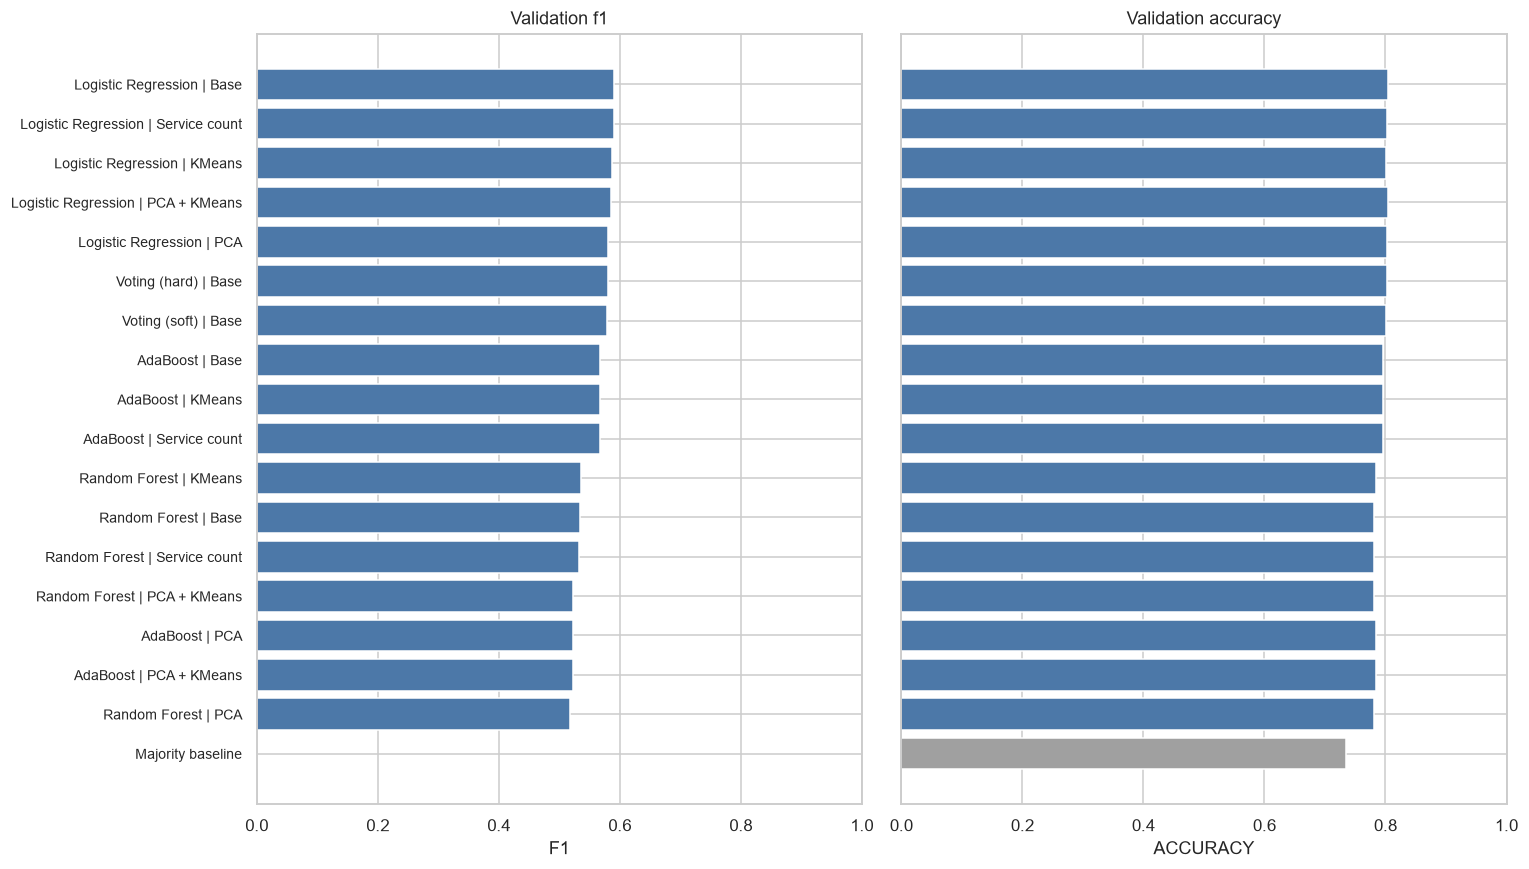

In [9]:
ordered = validation.sort_values("f1")
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
positions = np.arange(len(ordered))
for ax, metric in zip(axes, ["f1", "accuracy"]):
    ax.barh(positions, ordered[metric], color=["#a0a0a0" if name == "Majority baseline" else "#4c78a8" for name in ordered["model"]])
    ax.set(xlabel=metric.upper(), xlim=(0, 1), title=f"Validation {metric}")
axes[0].set_yticks(positions, ordered["model"], fontsize=9)
show_plot("05_validation_comparison.png")


## 7 Inspecting representations and model reliance

The following diagnostics come from training-fitted pipelines. The feature-importance plot permutes validation columns and measures the change in F1. It describes predictive reliance, not a causal effect. It is not used to remove features or tune the final test evaluation.


,model,encoded_features,pca_components,retained_variance,clusters,silhouette
0,Majority baseline,45,NaN,NaN,NaN,NaN
1,Random Forest | Base,45,NaN,NaN,NaN,NaN
2,AdaBoost | Base,45,NaN,NaN,NaN,NaN
3,Logistic Regression | Base,45,NaN,NaN,NaN,NaN
4,Random Forest | Service count,46,NaN,NaN,NaN,NaN
5,AdaBoost | Service count,46,NaN,NaN,NaN,NaN
6,Logistic Regression | Service count,46,NaN,NaN,NaN,NaN
7,Random Forest | PCA,45,18.0,0.958,NaN,NaN
8,AdaBoost | PCA,45,18.0,0.958,NaN,NaN
9,Logistic Regression | PCA,45,18.0,0.958,NaN,NaN


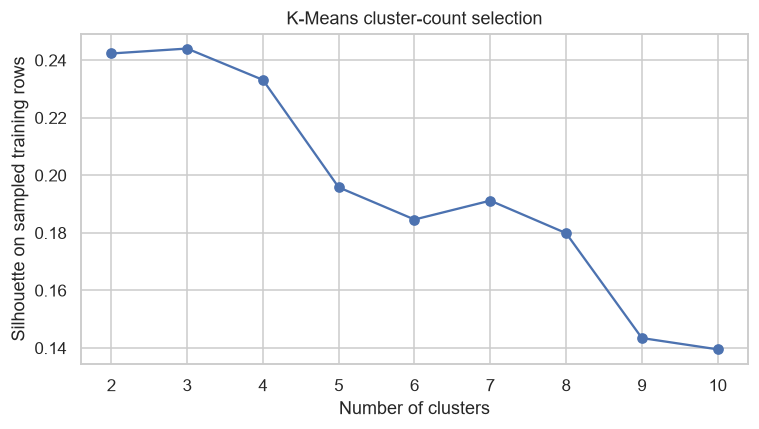

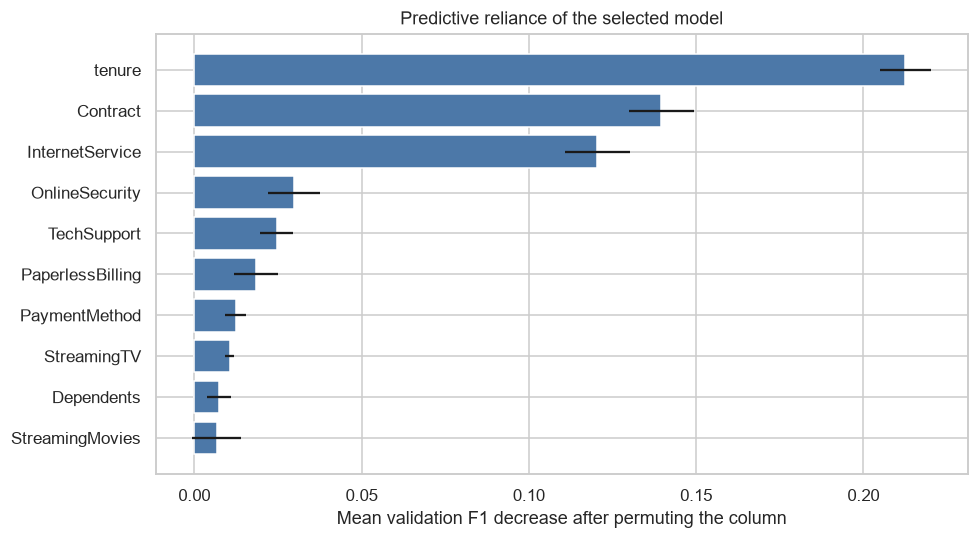

In [10]:
from sklearn.inspection import permutation_importance

representation_rows = []
for name, model in candidates.items():
    row = {"model": name, "encoded_features": len(model.named_steps["preprocess"].get_feature_names_out())}
    if "pca" in model.named_steps:
        row.update(pca_components=int(model.named_steps["pca"].n_components_), retained_variance=float(model.named_steps["pca"].explained_variance_ratio_.sum()))
    if "clusters" in model.named_steps:
        cluster = model.named_steps["clusters"]
        row.update(clusters=cluster.n_clusters_, silhouette=cluster.silhouette_scores_[cluster.n_clusters_])
    representation_rows.append(row)
representations = pd.DataFrame(representation_rows)
representations.to_csv(RESULTS / "representation_diagnostics.csv", index=False)
display(representations.round(3))

cluster_example = candidates["Random Forest | KMeans"].named_steps["clusters"]
plt.figure(figsize=(7, 4))
plt.plot(list(cluster_example.silhouette_scores_), list(cluster_example.silhouette_scores_.values()), "o-")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette on sampled training rows")
plt.title("K-Means cluster-count selection")
show_plot("06_cluster_selection.png")

importance = permutation_importance(candidates[best_name], X_validation, y_validation, scoring="f1", n_repeats=3, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({"feature": X.columns, "mean_f1_drop": importance.importances_mean, "std": importance.importances_std}).sort_values("mean_f1_drop", ascending=False)
importance_table.to_csv(RESULTS / "validation_permutation_importance.csv", index=False)
top = importance_table.head(10).sort_values("mean_f1_drop")
plt.figure(figsize=(9, 5))
plt.barh(top["feature"], top["mean_f1_drop"], xerr=top["std"], color="#4c78a8")
plt.xlabel("Mean validation F1 decrease after permuting the column")
plt.title("Predictive reliance of the selected model")
show_plot("07_permutation_importance.png")


## 8 Final held-out evaluation

The selected approach is now refitted on the combined training and validation partitions. Its preprocessing is relearned from those development rows. No model or feature choices are made from the test results. A single fixed split provides an estimate, not a guarantee for future customers or a proof that one approach is universally best.


,model,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,average_precision
0,Logistic Regression | Base,0.806,0.657,0.559,0.604,0.727,0.842,0.633
1,Majority baseline,0.735,0.000,0.000,0.000,0.500,0.500,0.265


,precision,recall,f1-score,support
Stayed,0.849,0.895,0.871,1035.000
Churned,0.657,0.559,0.604,374.000
accuracy,0.806,0.806,0.806,0.806
macro avg,0.753,0.727,0.738,1409.000
weighted avg,0.798,0.806,0.800,1409.000


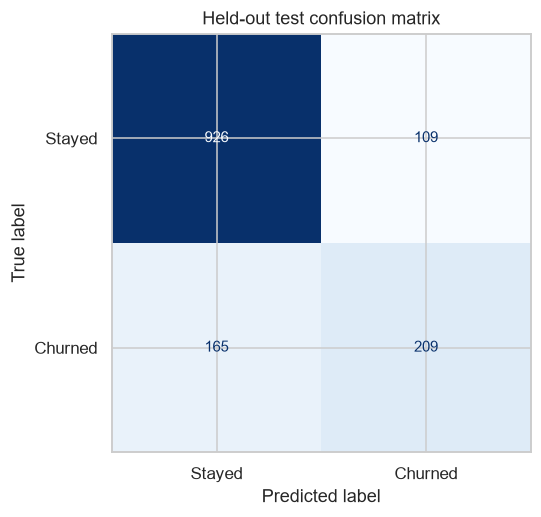

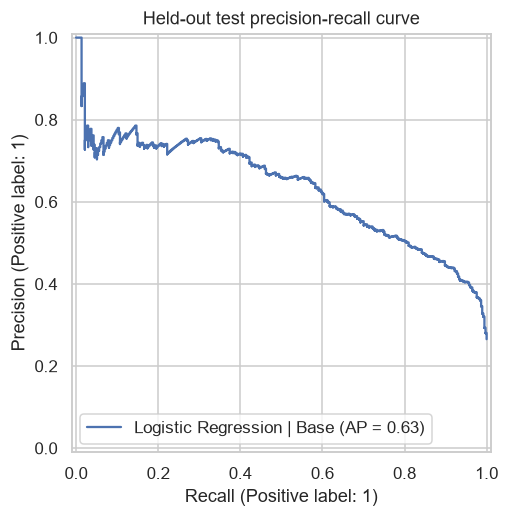

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

X_development, y_development = X.iloc[development_idx], y.iloc[development_idx]
final_model = clone(candidates[best_name]).fit(X_development, y_development)
test_scores, test_prediction, test_probability = evaluate(final_model, X_test, y_test)
baseline_model = clone(candidates["Majority baseline"]).fit(X_development, y_development)
baseline_scores, _, _ = evaluate(baseline_model, X_test, y_test)
final_result = {**selection, "test_rows": len(test_idx), "test_metrics": test_scores, "majority_baseline_test_metrics": baseline_scores}
(RESULTS / "test_metrics.json").write_text(json.dumps(final_result, indent=2, allow_nan=False))
predictions = pd.DataFrame({"customerID": df.iloc[test_idx]["customerID"].to_numpy(), "actual_churn": y_test.to_numpy(), "predicted_churn": test_prediction})
if test_probability is not None:
    predictions["churn_probability"] = test_probability
predictions.to_csv(RESULTS / "test_predictions.csv", index=False)
display(pd.DataFrame([{"model": best_name, **test_scores}, {"model": "Majority baseline", **baseline_scores}]).round(3))
display(pd.DataFrame(classification_report(y_test, test_prediction, target_names=["Stayed", "Churned"], output_dict=True, zero_division=0)).T.round(3))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Stayed", "Churned"], cmap="Blues", colorbar=False)
plt.title("Held-out test confusion matrix")
show_plot("08_test_confusion_matrix.png")
if test_probability is not None:
    PrecisionRecallDisplay.from_predictions(y_test, test_probability, name=best_name)
    plt.title("Held-out test precision-recall curve")
    show_plot("09_test_precision_recall.png")


## 9 Validation of the workflow and reproducibility

These checks verify disjoint dataset partitions, exclusion of identity and target columns from predictors, preprocessing fitted on training rows, sequential cell execution, and complete experiment outputs.


In [12]:
assert "customerID" not in X.columns and "Churn" not in X.columns
assert len(validation) == 18 and validation["model"].is_unique
assert validation[["accuracy", "precision", "recall", "f1"]].notna().all().all()
assert len(test_prediction) == len(test_idx)
assert set(np.unique(test_prediction)).issubset({0, 1})
for name, fitted in candidates.items():
    numeric_pipe = fitted.named_steps["preprocess"].named_transformers_["numeric"]
    assert int(numeric_pipe.named_steps["scale"].n_samples_seen_) == len(train_idx)
    learned_median = numeric_pipe.named_steps["imputer"].statistics_[NUMERIC.index("TotalCharges")]
    assert np.isclose(learned_median, X_train["TotalCharges"].median())
    if "pca" in fitted.named_steps:
        assert fitted.named_steps["pca"].n_samples_ == len(train_idx)
    if "clusters" in fitted.named_steps:
        assert fitted.named_steps["clusters"].n_samples_fit_ == len(train_idx)

versions = {package: metadata.version(package) for package in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "scipy", "nbformat", "nbclient", "nbconvert", "ipykernel"]}
run_metadata = {
    "python": platform.python_version(), "packages": versions, "seed": SEED,
    "dataset_sha256": hashlib.sha256(DATA.read_bytes()).hexdigest(),
    "dataset_rows": len(df), "dataset_columns": len(raw_columns), "blank_total_charges": blank_charges,
    "train_rows": len(train_idx), "validation_rows": len(validation_idx), "test_rows": len(test_idx),
    "candidate_models": len(candidates)-1, "baseline_models": 1,
    "selection_metric": "validation churn F1", "validation_checks_passed": True,
}
(RESULTS / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
display(Markdown(
    f"### Conclusions from this run\n\n"
    f"The selected model is **{best_name}**, chosen using validation churn F1. "
    f"On the untouched test partition of **{len(test_idx):,} customers**, it reached "
    f"**{test_scores['accuracy']:.1%} accuracy**, **{test_scores['f1']:.3f} churn F1**, "
    f"and **{test_scores['recall']:.1%} churn recall**. "
    f"The majority baseline accuracy was **{baseline_scores['accuracy']:.1%}**.\n\n"
    "PCA and clustering are experimental preprocessing alternatives; their use does not itself imply improvement. "
    "The comparison table records their measured validation performance. Group-rate charts are descriptive associations, "
    "and a single holdout evaluation has sampling uncertainty. These are academic experimental results, not evidence of production performance."
))
print("All workflow checks passed. Results and figures were saved in results/.")


### Conclusions from this run

The selected model is **Logistic Regression | Base**, chosen using validation churn F1. On the untouched test partition of **1,409 customers**, it reached **80.6% accuracy**, **0.604 churn F1**, and **55.9% churn recall**. The majority baseline accuracy was **73.5%**.

PCA and clustering are experimental preprocessing alternatives; their use does not itself imply improvement. The comparison table records their measured validation performance. Group-rate charts are descriptive associations, and a single holdout evaluation has sampling uncertainty. These are academic experimental results, not evidence of production performance.

All workflow checks passed. Results and figures were saved in results/.
